# Synthetic spectra generation

Sample M-dwarf stellar parameters from empirical distributions, synthesize spectra across four diagnostically motivated spectral windows (positive control 8800–8835 Å, Ca II IRT 8640 - 8710 Å, TiO molecular bands 8160 - 8225 Å, and K I + TiO 7640 - 7725 Å) at CARMENES VIS resolution (R = 94 600) using Korg, and persist each window as a separate Parquet file for downstream model training.

## Setup

In [1]:
import sys
from pathlib import Path

IN_COLAB = "google.colab" in str(get_ipython())

if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    REPO_ROOT = Path("/content/drive/MyDrive/spectral-windows-for-m-dwarf-host-stars")

    import subprocess

    subprocess.run(
        ["pip", "install", "-q", "juliacall==0.9.27", "juliapkg==0.1.18"],
        check=True,
    )
else:
    REPO_ROOT = Path.cwd().parents[1]

sys.path.insert(0, str(REPO_ROOT))
print("REPO_ROOT:", REPO_ROOT)

from src.datagen import install_korg

install_korg()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
REPO_ROOT: /content/drive/MyDrive/spectral-windows-for-m-dwarf-host-stars
Detected IPython. Loading juliacall extension. See https://juliapy.github.io/PythonCall.jl/stable/compat/#IPython


In [2]:
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import spearmanr
import numpy as np

import src.datavis as datavis

from src.datagen import (
    generate_synthetic_spectra_dataset,
    synthesize_spectra_from_stars,
    teff_from_radius_mann2015,
    _load_korg,
)
from src.dataset import _save_spectra_parquet

2026-05-12 13:24:01.515052: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2026-05-12 13:24:03.532130: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


M-dwarf physical ranges. Teff range source: https://www.pas.rochester.edu/~emamajek/EEM_dwarf_UBVIJHK_colors_Teff.txt

In [ ]:
EFFECTIVE_TEMP_RANGE_K = (2800, 3850.0)  # Teff in Kelvin
METALLICITY_FEH_RANGE = (
    -0.55,
    0.20,
)  # [Fe/H] in dex; inside Bonfils+2005 and Mann+2015 calibration domains
MASS_RANGE_MSUN = (
    0.08,
    0.57,
)  # M_sun; inside Mann+2019 0.075-0.70 M_sun calibration domain

NUM_SAMPLES = 5000

## Generate data

In [ ]:
stars = generate_synthetic_spectra_dataset(
    num_samples=NUM_SAMPLES,
    teff_range_K=EFFECTIVE_TEMP_RANGE_K,
    feh_range_dex=METALLICITY_FEH_RANGE,
    mass_range_msun=MASS_RANGE_MSUN,
    synthesize=False,
)

df_stars = pd.DataFrame(stars)
df_stars.head()

Synthesizing spectra...:   0%|          | 0/5000 [00:00<?, ?sample/s]

,Teff_K,logg_cgs,FeH_dex,Mass_Msun,Radius_Rsun
0,3579.446357,4.763662,-0.147870,0.399860,0.434133
1,2976.648214,5.215524,-0.403439,0.109080,0.134776
2,3751.436959,4.782187,-0.346634,0.438182,0.444871
3,3234.390821,4.971277,0.094085,0.271940,0.281902
4,3384.269202,5.035957,-0.356370,0.289908,0.270179


In [3]:
BASE_PATH = REPO_ROOT / "data"

In [ ]:
df_stars.to_parquet(BASE_PATH / "all_stars.parquet", engine="pyarrow", index=False)

## Visualize

### Stars Parameters

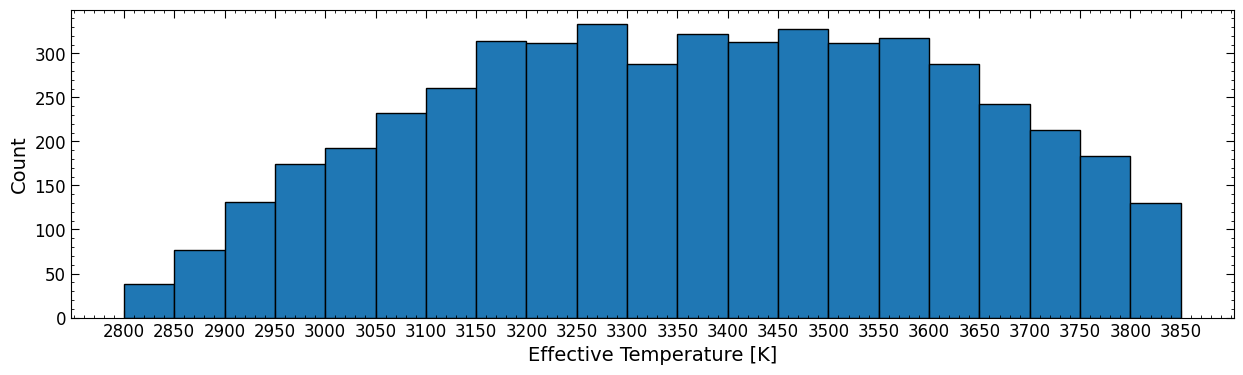

In [ ]:
datavis.plot_histogram(
    df_stars,
    "Teff_K",
    (2800, 3850),
    50,
    xlabel="Effective Temperature [K]",
    figsize=(15, 4),
)
plt.show()

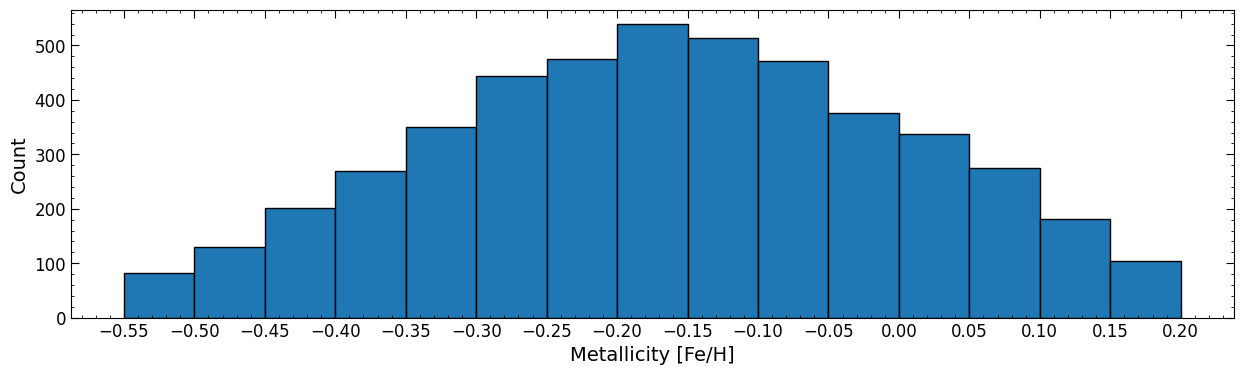

In [ ]:
datavis.plot_histogram(
    df_stars,
    "FeH_dex",
    METALLICITY_FEH_RANGE,
    0.05,
    xlabel="Metallicity [Fe/H]",
    figsize=(15, 4),
)
plt.show()

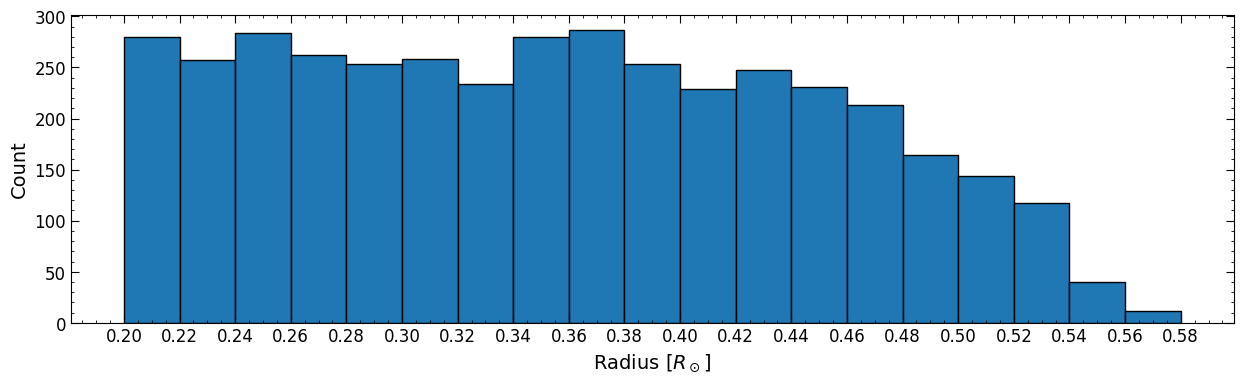

In [ ]:
datavis.plot_histogram(
    df_stars,
    "Radius_Rsun",
    (0.2, 0.58),
    0.02,
    xlabel=r"Radius [$R_\odot$]",
    figsize=(15, 4),
)
plt.show()

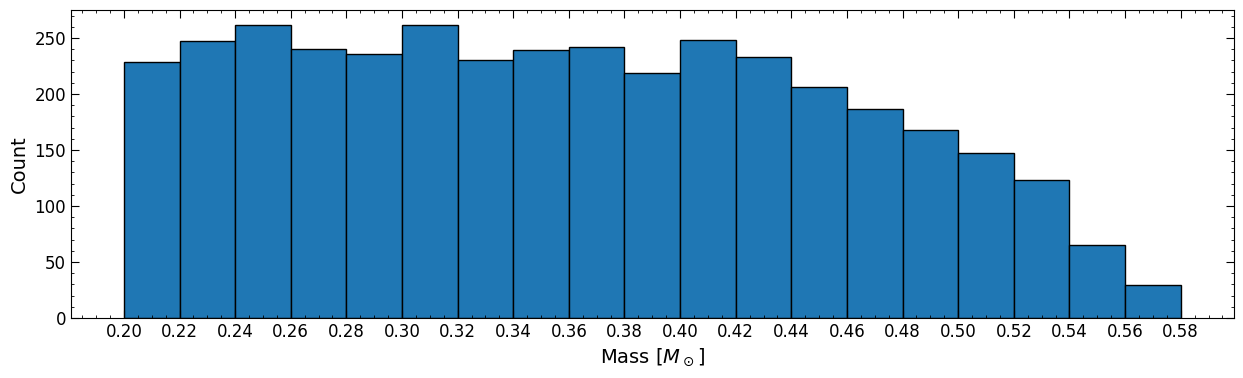

In [ ]:
datavis.plot_histogram(
    df_stars,
    "Mass_Msun",
    (0.2, 0.58),
    0.02,
    xlabel=r"Mass [$M_\odot$]",
    figsize=(15, 4),
)
plt.show()

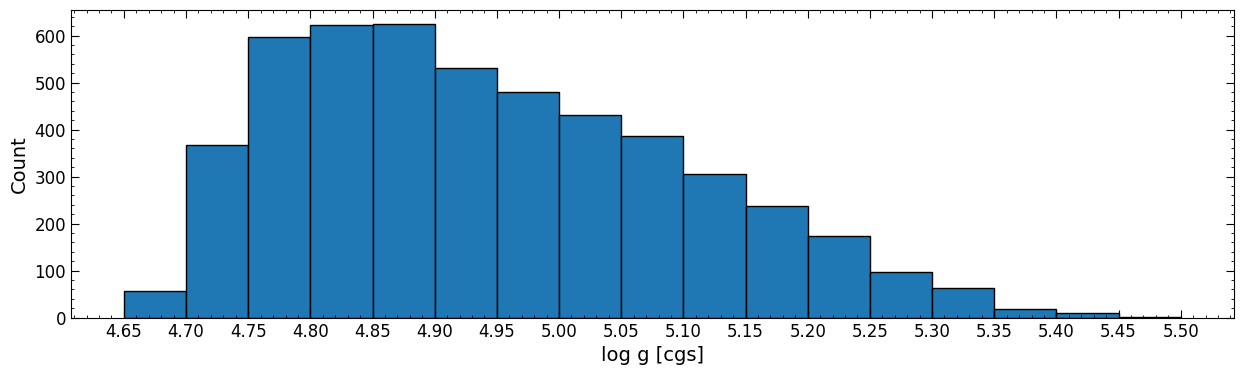

In [ ]:
datavis.plot_histogram(
    df_stars,
    "logg_cgs",
    (4.65, 5.5),
    0.05,
    xlabel="log g [cgs]",
    figsize=(15, 4),
)
plt.show()

### Physical Consistency Audit

This audit checks the two Mann constraints used by the parameter generator. Mann et al. (2015, ApJ 804, 64) provides the empirical radius-temperature-metallicity relation used to derive Teff from each generated radius and [Fe/H]:

$$R_{\star,\rm MS} = (a + b\tau + c\tau^2 + d\tau^3)(1 + f[\mathrm{Fe/H}]), \qquad \tau = T_{\rm eff}/3500\,\mathrm{K}.$$

The generator inverts that relation and then adds the quoted Teff calibration scatter. That residual depends strongly on the local slope of the Mann curve. Instead, Panel B compares the generated Teff to the zero-scatter Mann+2015 Teff implied by the same radius and metallicity.

Mann et al. (2019, ApJ 871, 63) is a mass-luminosity-metallicity calibration in absolute Ks magnitude, not a direct Teff-mass or radius-mass law. Since this notebook does not generate `M_Ks`, Mann+2019 is used here only as a domain check: the sampled masses stay inside its calibrated 0.075-0.70 Msun range.

**Panel A** shows the generated Teff-radius sample against the Mann+2015 solar-metallicity locus and the metallicity envelope from the sampled [Fe/H] range. **Panel B** shows the injected Teff residual; it should be centered near zero with a scatter close to 60 K.

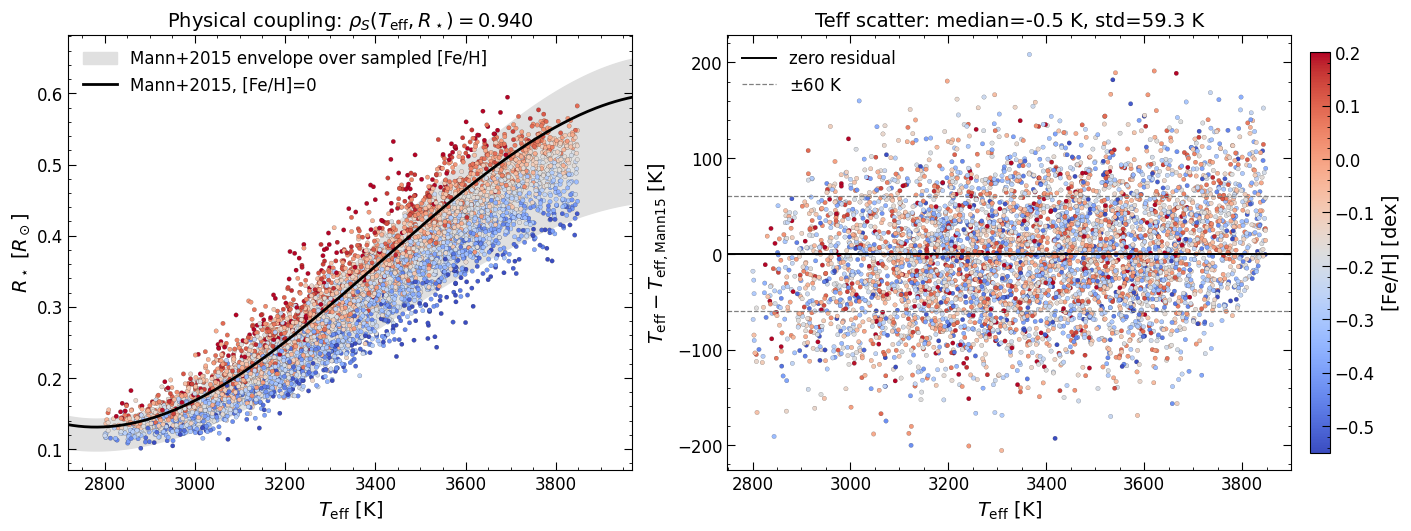

In [ ]:
# Mann+2015 Table 1, Eq. 5 coefficients for R_star(Teff, [Fe/H])
_a, _b, _c, _d, _f = 16.7700, -54.3210, 57.6627, -19.6994, 0.45650
MANN2015_TEFF_SCATTER_K = 60.0
MANN2015_RADIUS_SCATTER_FRAC = 0.093
MANN2019_MASS_RANGE_MSUN = (0.075, 0.70)


def mann2015_radius_from_teff(teff_K, feh_dex):
    tau = np.asarray(teff_K, dtype=float) / 3500.0
    return (_a + _b * tau + _c * tau**2 + _d * tau**3) * (
        1.0 + _f * np.asarray(feh_dex, dtype=float)
    )


# Reference loci for the displayed Teff interval.
teff_locus = np.linspace(2700.0, 4100.0, 300)
radius_locus_solar = mann2015_radius_from_teff(teff_locus, 0.0)
radius_locus_low_feh = mann2015_radius_from_teff(teff_locus, METALLICITY_FEH_RANGE[0])
radius_locus_high_feh = mann2015_radius_from_teff(teff_locus, METALLICITY_FEH_RANGE[1])

# Deterministic Mann+2015 Teff implied by each generated radius and [Fe/H].
teff_mann2015_nominal = np.array(
    [
        teff_from_radius_mann2015(radius, feh, scatter_K=0.0)
        for radius, feh in zip(df_stars["Radius_Rsun"], df_stars["FeH_dex"])
    ]
)
teff_resid = df_stars["Teff_K"].to_numpy() - teff_mann2015_nominal

radius_expected_from_observed_teff = mann2015_radius_from_teff(
    df_stars["Teff_K"],
    df_stars["FeH_dex"],
)
radius_resid_frac = (
    df_stars["Radius_Rsun"] - radius_expected_from_observed_teff
) / radius_expected_from_observed_teff
within_mann2019_mass_domain = df_stars["Mass_Msun"].between(*MANN2019_MASS_RANGE_MSUN)

rho_teff_radius, _ = spearmanr(df_stars["Teff_K"], df_stars["Radius_Rsun"])
rho_mass_radius, _ = spearmanr(df_stars["Mass_Msun"], df_stars["Radius_Rsun"])

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), constrained_layout=True)

# Panel A: Teff-radius relation with the metallicity envelope.
ax = axes[0]
ax.fill_between(
    teff_locus,
    np.minimum(radius_locus_low_feh, radius_locus_high_feh),
    np.maximum(radius_locus_low_feh, radius_locus_high_feh),
    color="0.88",
    label="Mann+2015 envelope over sampled [Fe/H]",
)
sc0 = ax.scatter(
    df_stars["Teff_K"],
    df_stars["Radius_Rsun"],
    c=df_stars["FeH_dex"],
    cmap="coolwarm",
    s=10,
    linewidths=0.1,
    edgecolors="k",
    vmin=METALLICITY_FEH_RANGE[0],
    vmax=METALLICITY_FEH_RANGE[1],
)
ax.plot(teff_locus, radius_locus_solar, color="k", lw=2, label="Mann+2015, [Fe/H]=0")
ax.set_xlim(EFFECTIVE_TEMP_RANGE_K[0] - 80, EFFECTIVE_TEMP_RANGE_K[1] + 120)
ax.set_xlabel(r"$T_{\rm eff}$ [K]")
ax.set_ylabel(r"$R_\star$ [$R_\odot$]")
ax.set_title(
    rf"Physical coupling: $\rho_S(T_{{\rm eff}}, R_\star)={rho_teff_radius:.3f}$"
)
ax.legend()

# Panel B: Teff residual from the zero-scatter Mann+2015 inversion.
ax = axes[1]
sc1 = ax.scatter(
    df_stars["Teff_K"],
    teff_resid,
    c=df_stars["FeH_dex"],
    cmap="coolwarm",
    s=10,
    linewidths=0.1,
    edgecolors="k",
    vmin=METALLICITY_FEH_RANGE[0],
    vmax=METALLICITY_FEH_RANGE[1],
)
ax.axhline(0, color="k", lw=1.4, label="zero residual")
ax.axhline(+MANN2015_TEFF_SCATTER_K, color="gray", lw=0.9, ls="--")
ax.axhline(
    -MANN2015_TEFF_SCATTER_K,
    color="gray",
    lw=0.9,
    ls="--",
    label=rf"$\pm{MANN2015_TEFF_SCATTER_K:.0f}$ K",
)
ax.set_xlabel(r"$T_{\rm eff}$ [K]")
ax.set_ylabel(r"$T_{\rm eff} - T_{\rm eff,Mann15}$ [K]")
ax.set_title(
    rf"Teff scatter: median={np.median(teff_resid):+.1f} K, "
    rf"std={np.std(teff_resid, ddof=1):.1f} K"
)
ax.legend()

cbar = fig.colorbar(sc1, ax=axes, pad=0.015, shrink=0.92)
cbar.set_label(r"$[\mathrm{Fe/H}]$ [dex]")

figures_path = REPO_ROOT / "figures"
figures_path.mkdir(exist_ok=True)
plt.savefig(figures_path / "teff_radius_relation.png", dpi=300, bbox_inches="tight")
plt.show()

## Get the spectra

In [ ]:
korg = _load_korg()
BASE_PATH = REPO_ROOT / "data"
BASE_PATH.mkdir(exist_ok=True)

windows = {
    "controle_positivo": (8800.0, 8835.0),
    "triplete_ca_ii": (8640.0, 8710.0),
    "bandas_tio": (8160.0, 8225.0),
    "linhas_k_i_tio": (7640.0, 7725.0),
}

for window_name, window_A in windows.items():
    print(f"\n--- Window: {window_name} {window_A} ---")

    data = synthesize_spectra_from_stars(
        df_stars=df_stars,
        wavelength_window_A=window_A,
        R=94600,
        korg=korg,
    )

    df_spectra = pd.DataFrame(data)
    print(f"Synthesized: {len(df_spectra)}/{len(df_stars)} stars")

    _save_spectra_parquet(
        df_spectra=df_spectra,
        base_path=BASE_PATH,
        filename=f"spectra_{window_name}.parquet",
    )


--- Window: controle_positivo (8800.0, 8835.0) ---


Synthesizing spectra...:   0%|          | 0/5000 [00:00<?, ?sample/s]

Synthesized: 5000/5000 stars
Wrote c:\Users\Josué\Documents\Research\spectral-windows-for-m-dwarf-host-stars\data\spectra_controle_positivo.parquet

--- Window: triplete_ca_ii (8640.0, 8710.0) ---


Synthesizing spectra...:   0%|          | 0/5000 [00:00<?, ?sample/s]

Synthesized: 5000/5000 stars
Wrote c:\Users\Josué\Documents\Research\spectral-windows-for-m-dwarf-host-stars\data\spectra_triplete_ca_ii.parquet

--- Window: bandas_tio (8160.0, 8225.0) ---


Synthesizing spectra...:   0%|          | 0/5000 [00:00<?, ?sample/s]

Synthesized: 5000/5000 stars
Wrote c:\Users\Josué\Documents\Research\spectral-windows-for-m-dwarf-host-stars\data\spectra_bandas_tio.parquet

--- Window: linhas_k_i_tio (7640.0, 7725.0) ---


Synthesizing spectra...:   0%|          | 0/5000 [00:00<?, ?sample/s]

Synthesized: 5000/5000 stars
Wrote c:\Users\Josué\Documents\Research\spectral-windows-for-m-dwarf-host-stars\data\spectra_linhas_k_i_tio.parquet


### Windows

#### Positive Control 8800–8835 Å

In [4]:
df_positive_control = pd.read_parquet(BASE_PATH / "spectra_controle_positivo.parquet")
df_positive_control.head()

,Teff_K,logg_cgs,FeH_dex,Mass_Msun,Radius_Rsun,wavelength_A,flux,continuum
0,3579.446357,4.763662,-0.147870,0.399860,0.434133,"[8800.0, 8800.009765625, 8800.01953125, 8800.0...","[0.9989299774169922, 0.9989288449287415, 0.998...","[896114.6875, 896114.125, 896113.5, 896112.937..."
1,2976.648214,5.215524,-0.403439,0.109080,0.134776,"[8800.0, 8800.009765625, 8800.01953125, 8800.0...","[0.9994313716888428, 0.9994310140609741, 0.999...","[501204.09375, 501204.09375, 501204.09375, 501..."
2,3751.436959,4.782187,-0.346634,0.438182,0.444871,"[8800.0, 8800.009765625, 8800.01953125, 8800.0...","[0.998831570148468, 0.9988303184509277, 0.9988...","[1011267.6875, 1011266.875, 1011266.125, 10112..."
3,3234.390821,4.971277,0.094085,0.271940,0.281902,"[8800.0, 8800.009765625, 8800.01953125, 8800.0...","[0.9991707801818848, 0.9991700649261475, 0.999...","[672918.1875, 672918.0, 672917.75, 672917.5, 6..."
4,3384.269202,5.035957,-0.356370,0.289908,0.270179,"[8800.0, 8800.009765625, 8800.01953125, 8800.0...","[0.9992481470108032, 0.9992473721504211, 0.999...","[729171.8125, 729171.5, 729171.1875, 729170.87..."


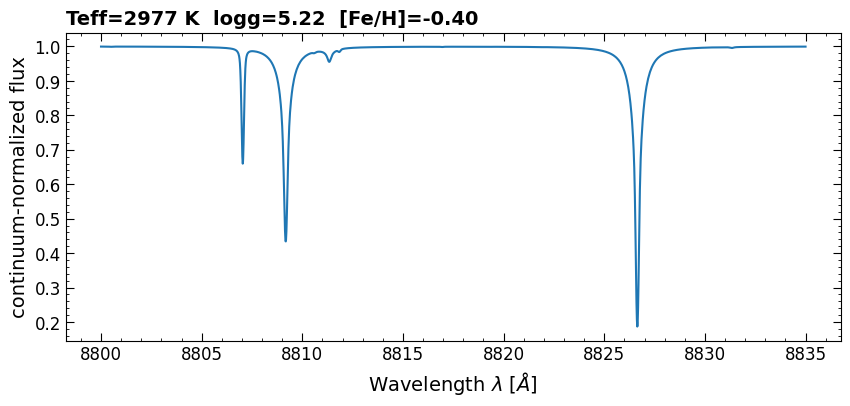

In [5]:
datavis.plot_single_spectrum(df_positive_control, row_index=1)
plt.show()

(<Figure size 1200x1000 with 6 Axes>,
 array([<Axes: ylabel='Continuum-normalized flux'>,
        <Axes: ylabel='Continuum-normalized flux'>,
        <Axes: xlabel='Wavelength $\\lambda$ [$\\AA$]', ylabel='Continuum-normalized flux'>],
       dtype=object))

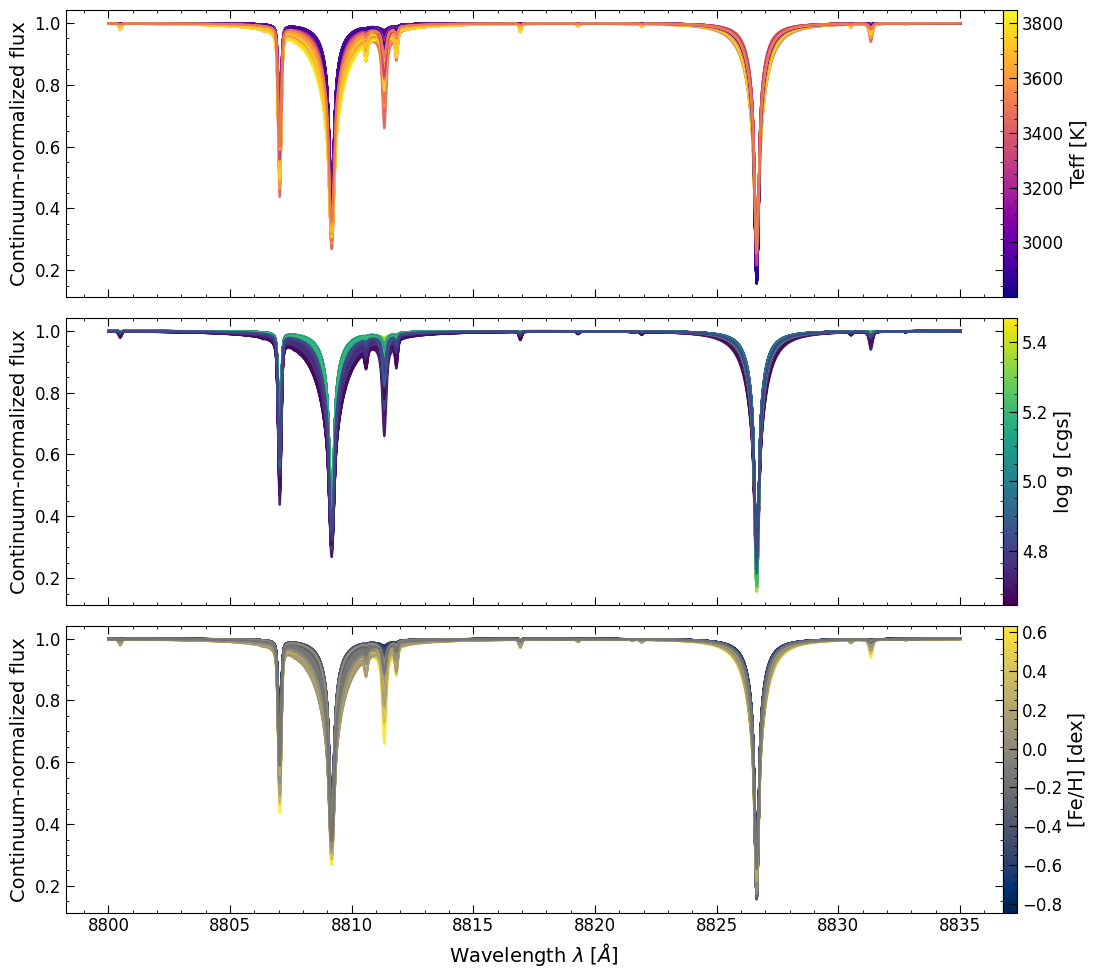

In [6]:
datavis.plot_spectra_colored_by_params(df_positive_control)

### Ca II IRT 8640–8710 Å

In [5]:
df_Ca_II_IRT = pd.read_parquet(BASE_PATH / "spectra_triplete_ca_ii.parquet")
df_Ca_II_IRT.head()

,Teff_K,logg_cgs,FeH_dex,Mass_Msun,Radius_Rsun,wavelength_A,flux,continuum
0,3579.446357,4.763662,-0.147870,0.399860,0.434133,"[8640.0, 8640.009765625, 8640.01953125, 8640.0...","[0.9984549283981323, 0.9984546899795532, 0.998...","[904879.125, 904878.625, 904878.0625, 904877.5..."
1,2976.648214,5.215524,-0.403439,0.109080,0.134776,"[8640.0, 8640.009765625, 8640.01953125, 8640.0...","[0.9995380640029907, 0.9995381832122803, 0.999...","[500969.40625, 500969.4375, 500969.46875, 5009..."
2,3751.436959,4.782187,-0.346634,0.438182,0.444871,"[8640.0, 8640.009765625, 8640.01953125, 8640.0...","[0.9984259009361267, 0.998426079750061, 0.9984...","[1023294.75, 1023294.0, 1023293.25, 1023292.56..."
3,3234.390821,4.971277,0.094085,0.271940,0.281902,"[8640.0, 8640.009765625, 8640.01953125, 8640.0...","[0.9989907145500183, 0.9989908337593079, 0.998...","[676098.25, 676098.0625, 676097.875, 676097.75..."
4,3384.269202,5.035957,-0.356370,0.289908,0.270179,"[8640.0, 8640.009765625, 8640.01953125, 8640.0...","[0.9988667368888855, 0.9988666772842407, 0.998...","[733638.875, 733638.625, 733638.375, 733638.12..."


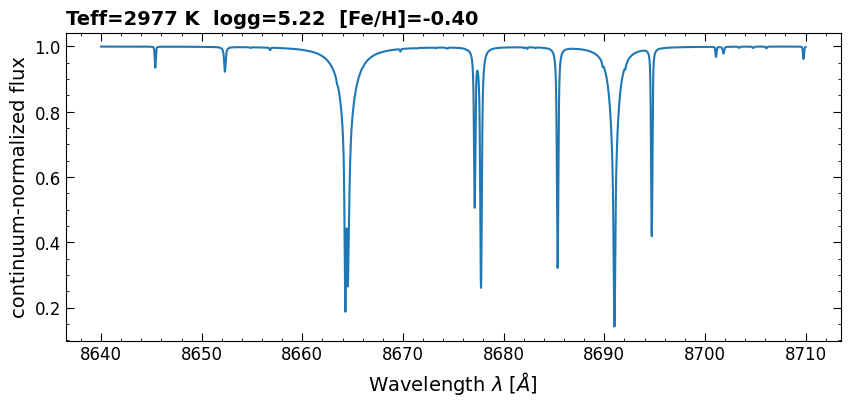

In [6]:
datavis.plot_single_spectrum(df_Ca_II_IRT, row_index=1)
plt.show()

(<Figure size 1200x1000 with 6 Axes>,
 array([<Axes: ylabel='Continuum-normalized flux'>,
        <Axes: ylabel='Continuum-normalized flux'>,
        <Axes: xlabel='Wavelength $\\lambda$ [$\\AA$]', ylabel='Continuum-normalized flux'>],
       dtype=object))

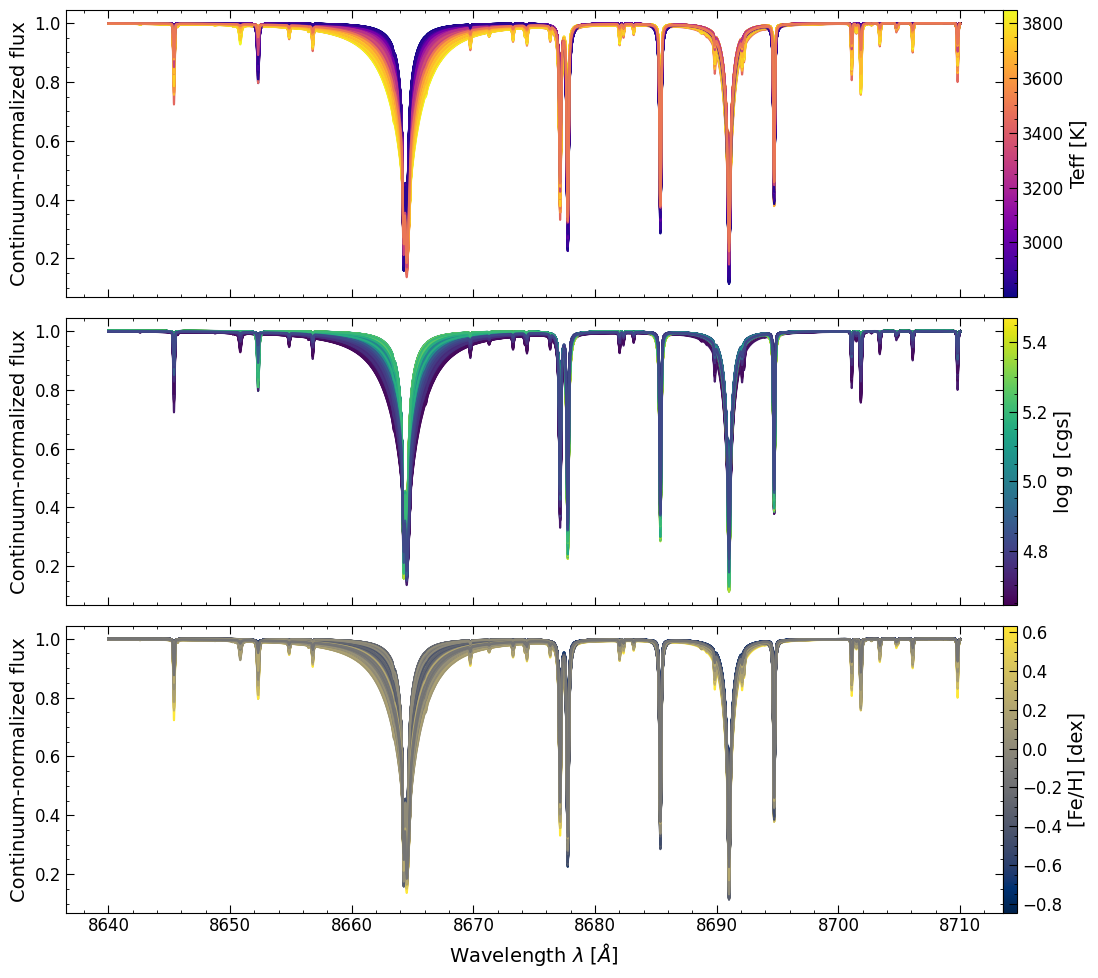

In [7]:
datavis.plot_spectra_colored_by_params(df_Ca_II_IRT)

### TiO molecular bands 8160–8225 Å

In [6]:
df_TiO_molecular_bands = pd.read_parquet(BASE_PATH / "spectra_bandas_tio.parquet")
df_TiO_molecular_bands.head()

,Teff_K,logg_cgs,FeH_dex,Mass_Msun,Radius_Rsun,wavelength_A,flux,continuum
0,3579.446357,4.763662,-0.147870,0.399860,0.434133,"[8160.0, 8160.009765625, 8160.02001953125, 816...","[0.9991223812103271, 0.9991220831871033, 0.999...","[926170.9375, 926170.5625, 926170.1875, 926169..."
1,2976.648214,5.215524,-0.403439,0.109080,0.134776,"[8160.0, 8160.009765625, 8160.02001953125, 816...","[0.9922040104866028, 0.9922017455101013, 0.992...","[496079.75, 496079.90625, 496080.09375, 496080..."
2,3751.436959,4.782187,-0.346634,0.438182,0.444871,"[8160.0, 8160.009765625, 8160.02001953125, 816...","[0.9994925260543823, 0.9994922876358032, 0.999...","[1054535.875, 1054535.25, 1054534.75, 1054534...."
3,3234.390821,4.971277,0.094085,0.271940,0.281902,"[8160.0, 8160.009765625, 8160.02001953125, 816...","[0.9965274333953857, 0.9965264201164246, 0.996...","[680781.9375, 680781.9375, 680781.9375, 680781..."
4,3384.269202,5.035957,-0.356370,0.289908,0.270179,"[8160.0, 8160.009765625, 8160.02001953125, 816...","[0.9981229901313782, 0.9981224536895752, 0.998...","[742035.625, 742035.5625, 742035.4375, 742035...."


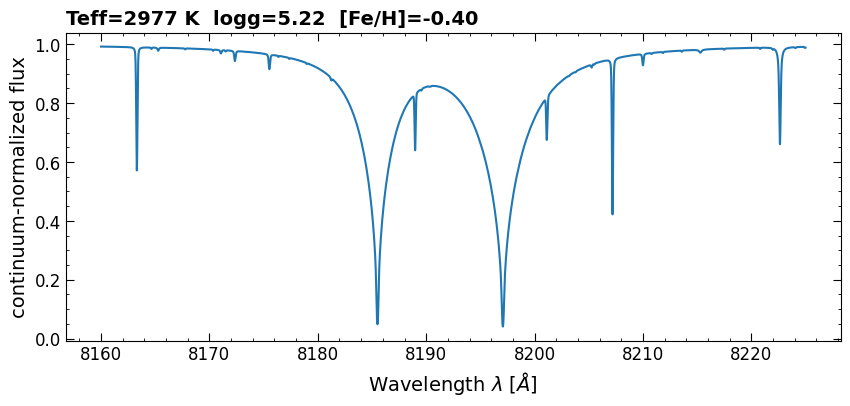

In [7]:
datavis.plot_single_spectrum(df_TiO_molecular_bands, row_index=1)
plt.show()

(<Figure size 1200x1000 with 6 Axes>,
 array([<Axes: ylabel='Continuum-normalized flux'>,
        <Axes: ylabel='Continuum-normalized flux'>,
        <Axes: xlabel='Wavelength $\\lambda$ [$\\AA$]', ylabel='Continuum-normalized flux'>],
       dtype=object))

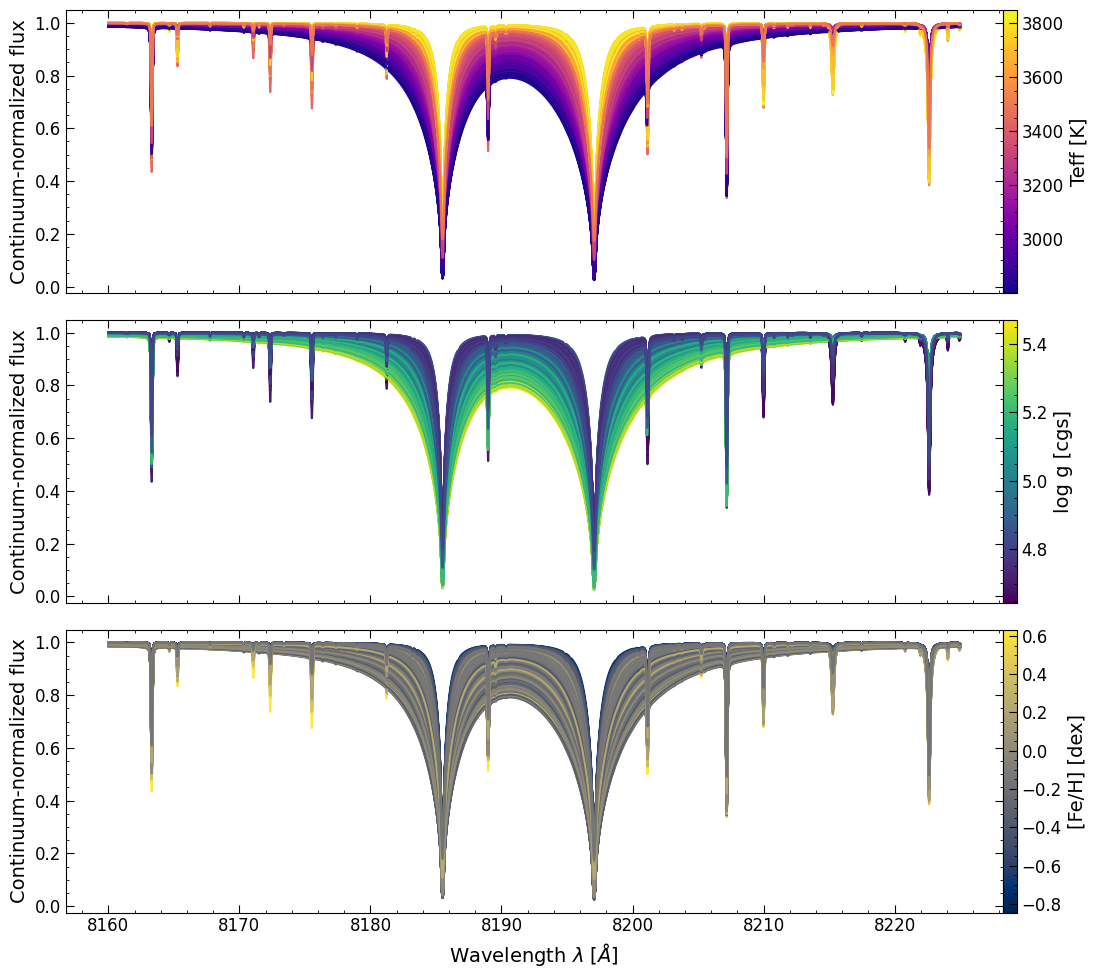

In [8]:
datavis.plot_spectra_colored_by_params(df_TiO_molecular_bands)

### K I + TiO 7640–7725 Å

In [4]:
df_K_I_TiO = pd.read_parquet(BASE_PATH / "spectra_linhas_k_i_tio.parquet")
df_K_I_TiO.head()

,Teff_K,logg_cgs,FeH_dex,Mass_Msun,Radius_Rsun,wavelength_A,flux,continuum
0,3579.446357,4.763662,-0.147870,0.399860,0.434133,"[7640.0, 7640.009765625, 7640.02001953125, 764...","[0.9991676807403564, 0.9991673827171326, 0.999...","[937693.6875, 937693.625, 937693.5625, 937693...."
1,2976.648214,5.215524,-0.403439,0.109080,0.134776,"[7640.0, 7640.009765625, 7640.02001953125, 764...","[0.9759690761566162, 0.9759619832038879, 0.975...","[482210.59375, 482210.96875, 482211.34375, 482..."
2,3751.436959,4.782187,-0.346634,0.438182,0.444871,"[7640.0, 7640.009765625, 7640.02001953125, 764...","[0.9996176362037659, 0.9996174573898315, 0.999...","[1076716.75, 1076716.5, 1076716.25, 1076716.0,..."
3,3234.390821,4.971277,0.094085,0.271940,0.281902,"[7640.0, 7640.009765625, 7640.02001953125, 764...","[0.995084822177887, 0.9950833916664124, 0.9950...","[675399.375, 675399.5625, 675399.8125, 675400...."
4,3384.269202,5.035957,-0.356370,0.289908,0.270179,"[7640.0, 7640.009765625, 7640.02001953125, 764...","[0.9977483749389648, 0.9977476596832275, 0.997...","[740206.8125, 740207.0, 740207.125, 740207.312..."


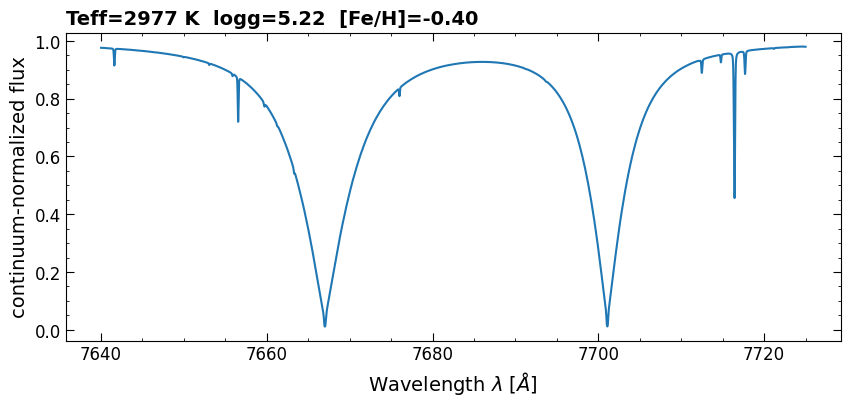

In [5]:
datavis.plot_single_spectrum(df_K_I_TiO, row_index=1)
plt.show()

(<Figure size 1200x1000 with 6 Axes>,
 array([<Axes: ylabel='Continuum-normalized flux'>,
        <Axes: ylabel='Continuum-normalized flux'>,
        <Axes: xlabel='Wavelength $\\lambda$ [$\\AA$]', ylabel='Continuum-normalized flux'>],
       dtype=object))

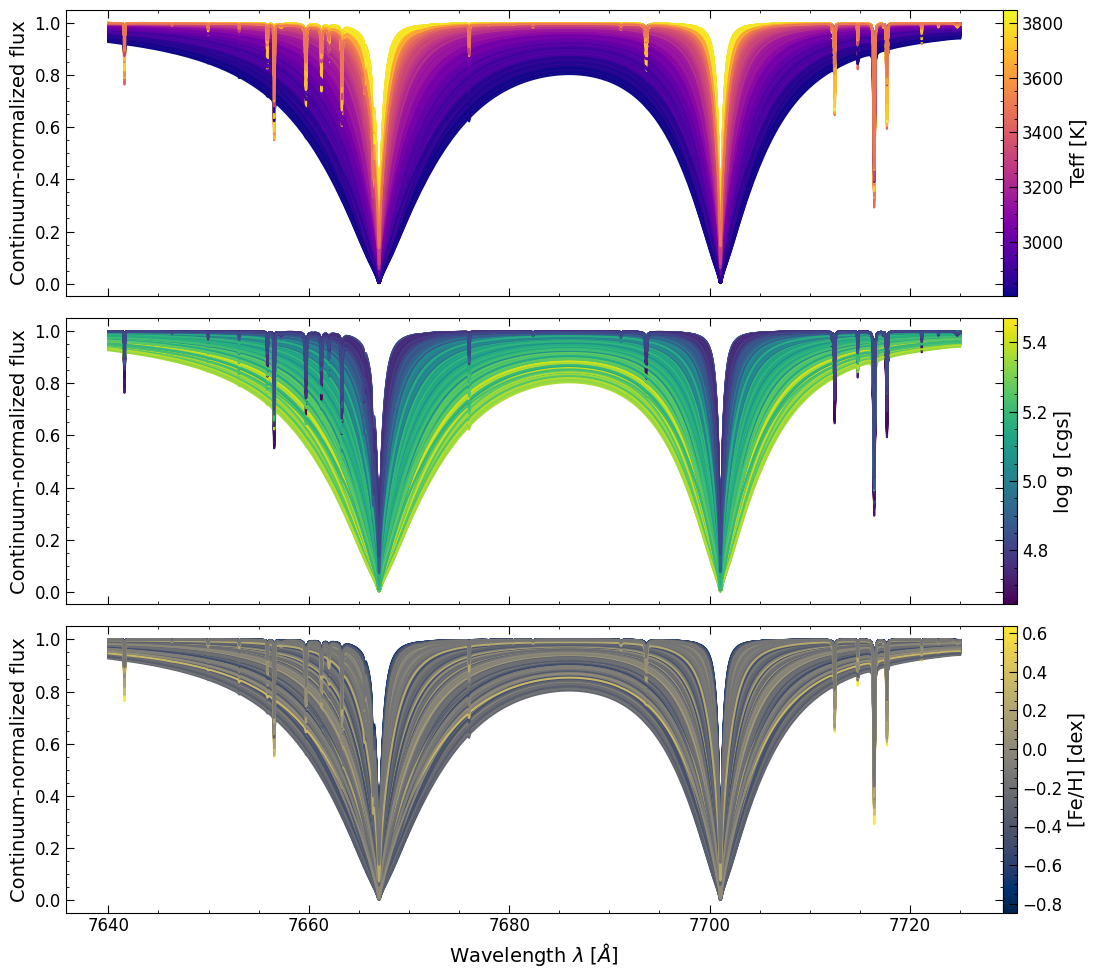

In [6]:
datavis.plot_spectra_colored_by_params(df_K_I_TiO)